# Member 4 – Model Evaluation and Comparative Analysis (Part G)

All models are evaluated with the same code (`src/evaluation.py`) on the same hold-out
test set created by Member 1. Each model is refitted on the full training set using its
frozen, cross-validated hyperparameters, then scored once on the test set.

* Classification threshold: 0.5 (agreed default, not tuned on the test set)
* Metrics: Accuracy, Precision, Recall, F1, ROC-AUC, Average Precision, Confusion Matrix
* Efficiency: training (fit) time and prediction time

The test set is **not** used for model or ensemble selection – that is done with the
shared 5-fold cross-validation results.

In [1]:
from pathlib import Path
import sys

# Find the project root (the folder that contains data/processed)
ROOT = Path.cwd()
while not (ROOT / "data" / "processed" / "split_manifest.json").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Run this notebook from inside the project folder.")
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from src.data_preparation import load_training_bundle
from src import evaluation as ev

X_train, y_train, metadata = load_training_bundle(ROOT)
X_test, y_test = ev.load_test_bundle(ROOT)

RESULTS = ROOT / "results" / "member4"
FIGURES = RESULTS / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)

print("Training records:", len(X_train), "| positive rate:", round(y_train.mean(), 4))
print("Test records:    ", len(X_test), "| positive rate:", round(y_test.mean(), 4))

Training records: 202795 | positive rate: 0.0942
Test records:     50885 | positive rate: 0.0943


## 1. Models to evaluate

* **Logistic Regression** and **Decision Tree** – rebuilt from Member 2's best parameters.
* **Random Forest** – rebuilt from Member 3's best parameters.
* **Soft Voting Ensemble** – Logistic Regression + Random Forest with equal weights, as
  selected by Member 3 using cross-validation Average Precision (table below). The
  Decision Tree was excluded because it had the lowest cross-validation scores.

In [2]:
selection = pd.read_csv(ROOT / "results/member3/model_selection_comparison.csv")
display(selection.round(4))

,Model,Average Precision,ROC-AUC,Recall,Selection
0,Logistic Regression,0.3689,0.8465,0.1222,Selected for ensemble
1,Random Forest,0.3653,0.8467,0.0706,Selected for ensemble
2,Decision Tree,0.3407,0.8340,0.0889,Excluded from ensemble
3,Soft Voting Ensemble,0.3723,0.8490,0.0970,Ensemble model


In [3]:
models = {
    "Logistic Regression": ev.optimised_logistic_regression(ROOT),
    "Decision Tree": ev.optimised_decision_tree(ROOT),
    "Random Forest": ev.optimised_random_forest(ROOT),
    "Soft Voting Ensemble": ev.soft_voting_ensemble(ROOT),
}
for name, model in models.items():
    print(name, "->", model)

# Cross-validation results for the training vs validation vs test comparison
cv_paths = {
    "Logistic Regression": ROOT / "results/member2/logistic_regression_optimised.csv",
    "Decision Tree": ROOT / "results/member2/decision_tree_optimised.csv",
    "Random Forest": ROOT / "results/member3/random_forest_optimised_cv.csv",
    "Soft Voting Ensemble": ROOT / "results/member3/soft_voting_ensemble.csv",
}

Logistic Regression -> Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['BMI', 'MentHlth',
                                                   'PhysHlth']),
                                                 ('binary',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['HighBP', 'HighChol',
                                                   'CholCheck', 'Smoker',
                                                   'Stroke', 'PhysActivity',
                              

## 2. Fit on the full training set and score on the test set

In [4]:
results = []
for name, model in models.items():
    results.append(ev.evaluate_model(name, model, X_train, y_train, X_test, y_test))
    print(f"{name}: done in {results[-1].fit_seconds:.2f} s")

Logistic Regression: done in 1.25 s


Decision Tree: done in 0.69 s


Random Forest: done in 5.12 s


Soft Voting Ensemble: done in 6.03 s


## 3. Test-set comparison table

In [5]:
comparison = ev.comparison_table(results)
comparison.to_csv(RESULTS / "test_comparison.csv")
display(comparison.round(4))

,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Fit Time (s),Predict Time (s)
Model,,,,,,,,
Logistic Regression,0.9083,0.5598,0.1289,0.2095,0.8490,0.3770,1.2505,0.0579
Decision Tree,0.9068,0.5271,0.1053,0.1755,0.8378,0.3511,0.6871,0.0213
Random Forest,0.9079,0.5896,0.0734,0.1305,0.8499,0.3810,5.1230,0.0720
Soft Voting Ensemble,0.9087,0.5922,0.1018,0.1737,0.8518,0.3837,6.0306,0.1004


## 4. Confusion matrices

,True Negative,False Positive,False Negative,True Positive,Specificity
Model,,,,,
Logistic Regression,45603,486,4178,618,0.9895
Decision Tree,45636,453,4291,505,0.9902
Random Forest,45844,245,4444,352,0.9947
Soft Voting Ensemble,45753,336,4308,488,0.9927


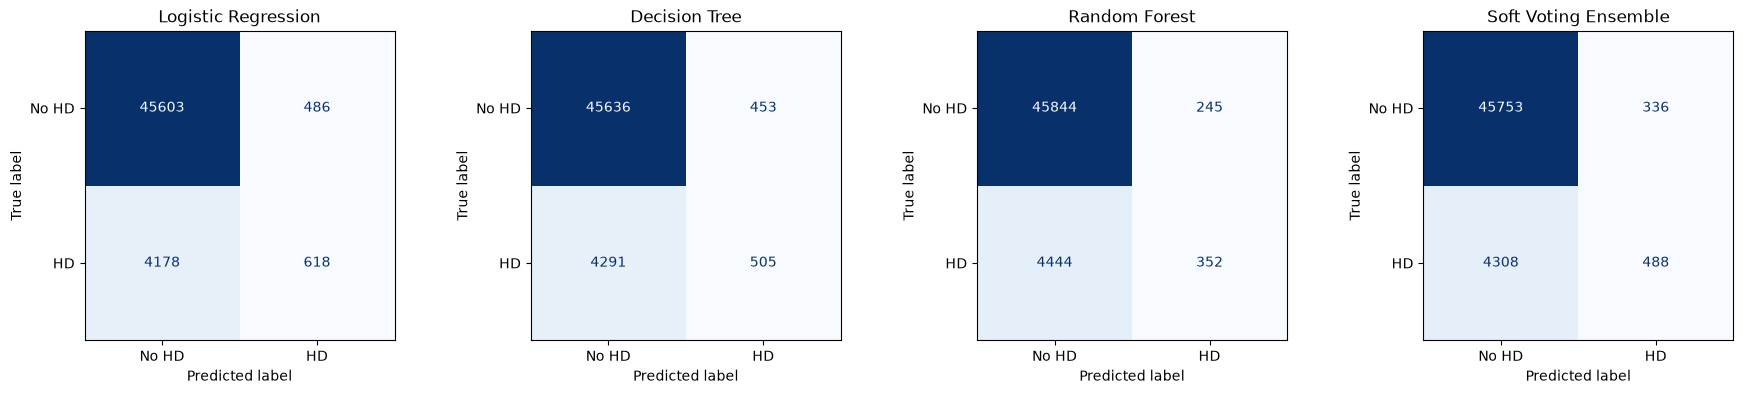

In [6]:
confusion = ev.confusion_table(results, y_test)
confusion.to_csv(RESULTS / "confusion_matrices.csv")
display(confusion.round(4))
ev.plot_confusion_matrices(results, y_test, FIGURES / "confusion_matrices.png");

## 5. Overfitting and underfitting check

Training scores, mean cross-validation scores (from each member's results) and test
scores side by side. A large training-minus-test gap indicates overfitting; low scores
on all three indicate underfitting.

In [7]:
generalisation = ev.generalisation_table(results, cv_paths)
generalisation.to_csv(RESULTS / "train_cv_test_gap.csv", index=False)
display(generalisation.round(4))

,Model,Metric,Training,CV Validation,Test,Train - Test Gap
0,Logistic Regression,Accuracy,0.9075,0.9074,0.9083,-0.0008
1,Logistic Regression,F1,0.1997,0.1991,0.2095,-0.0098
2,Logistic Regression,ROC_AUC,0.8469,0.8465,0.8490,-0.0021
3,Logistic Regression,Average_Precision,0.3693,0.3689,0.3770,-0.0077
4,Decision Tree,Accuracy,0.9091,0.9066,0.9068,0.0023
5,Decision Tree,F1,0.1940,0.1518,0.1755,0.0185
6,Decision Tree,ROC_AUC,0.8556,0.8340,0.8378,0.0178
7,Decision Tree,Average_Precision,0.3908,0.3407,0.3511,0.0397
8,Random Forest,Accuracy,0.9131,0.9075,0.9079,0.0052
9,Random Forest,F1,0.1884,0.1257,0.1305,0.0579


## 6. Performance graphs

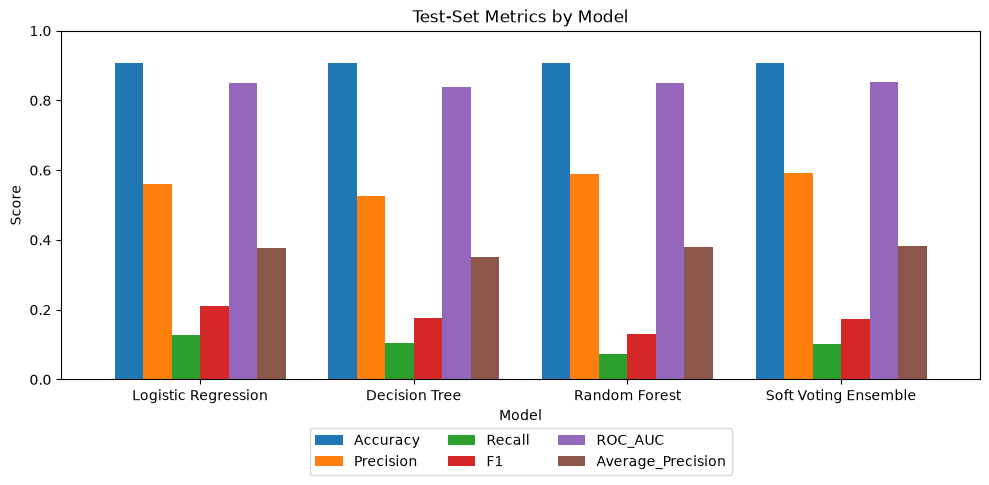

In [8]:
ev.plot_metric_bars(comparison, FIGURES / "test_metric_bars.png");

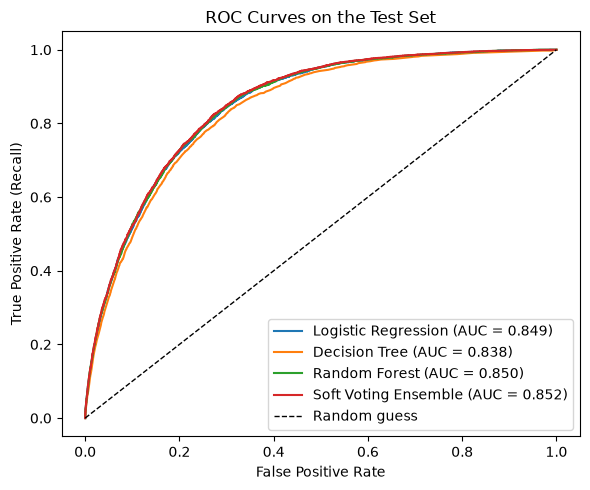

In [9]:
ev.plot_roc_curves(results, y_test, FIGURES / "roc_curves.png");

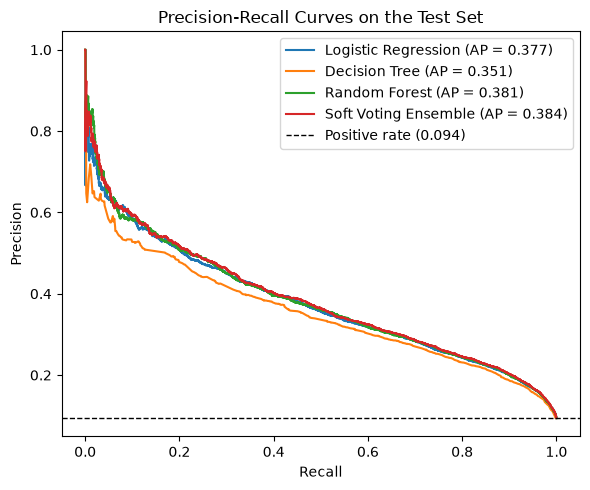

In [10]:
ev.plot_precision_recall_curves(results, y_test, FIGURES / "precision_recall_curves.png");

## 7. Computational efficiency

In [11]:
efficiency = comparison[["Fit Time (s)", "Predict Time (s)"]].copy()
efficiency["Predict Time per 1,000 rows (ms)"] = (
    efficiency["Predict Time (s)"] / len(X_test) * 1_000 * 1_000)
efficiency.to_csv(RESULTS / "efficiency.csv")
display(efficiency.round(4))

,Fit Time (s),Predict Time (s),"Predict Time per 1,000 rows (ms)"
Model,,,
Logistic Regression,1.2505,0.0579,1.1380
Decision Tree,0.6871,0.0213,0.4193
Random Forest,5.1230,0.0720,1.4151
Soft Voting Ensemble,6.0306,0.1004,1.9738


## 8. Does the ensemble significantly improve performance?

The ensemble is compared with its two component models using a paired bootstrap on the
test set (1,000 resamples). If the 95% interval of the difference contains 0, the
improvement is not statistically meaningful.

In [12]:
from sklearn.metrics import average_precision_score, roc_auc_score

by_name = {r.name: r for r in results}
ensemble = by_name["Soft Voting Ensemble"]
rows = []
for other in ["Logistic Regression", "Random Forest"]:
    for metric_name, metric in [("Average_Precision", average_precision_score),
                                ("ROC_AUC", roc_auc_score)]:
        rows.append({"Comparison": f"Ensemble - {other}", "Metric": metric_name,
                     **ev.bootstrap_difference(y_test, ensemble.test_probability,
                                               by_name[other].test_probability, metric)})
significance = pd.DataFrame(rows)
significance.to_csv(RESULTS / "ensemble_bootstrap.csv", index=False)
display(significance.round(4))

,Comparison,Metric,Difference,CI Lower,CI Upper,Share of Resamples > 0
0,Ensemble - Logistic Regression,Average_Precision,0.0067,0.0044,0.0092,1.000
1,Ensemble - Logistic Regression,ROC_AUC,0.0028,0.0019,0.0037,1.000
2,Ensemble - Random Forest,Average_Precision,0.0027,-0.0003,0.0057,0.964
3,Ensemble - Random Forest,ROC_AUC,0.0019,0.0011,0.0026,1.000


## 9. Points for the Part G discussion

* **Class imbalance:** only about 9.4% of people are positive, so accuracy alone is
  misleading – predicting "no heart disease" for everyone already scores about 90.6%.
  Recall, F1, ROC-AUC and Average Precision are more informative.
* **Threshold:** at the default 0.5 threshold both models have low recall (many missed
  cases). In a screening setting a lower threshold, chosen on validation data, may be
  more appropriate. This is a deployment decision, not something tuned on the test set.
* **Interpretability:** Logistic Regression gives coefficients/odds ratios; the Decision
  Tree gives readable rules and feature importance. Random Forest and the ensemble are
  harder to explain to clinicians.
* **Ensemble:** use the bootstrap table above to judge whether its gain over Logistic
  Regression and Random Forest is meaningful or within normal variation, and weigh any
  gain against the extra training time and lost interpretability.